# WP03 SIDER keşfi ve yan etki eşlemesi

**05.11.2026.** Bu notebook mevcut DrugBank/SIDER kaynakları arasında kimlik izlenebilirliğini araştırır. Her kod hücresinin altında gerçek hesaplanmış tablo/grafik vardır. Yalnız WP03: model, split, negatif örnek veya etiket temelli girdi yok. **Nihai 30 kategori tanımı değiştirilmedi**; PT-CUI pozitifleri keşif tablosudur, alternatif kategori projeksiyonları denetimdir.

Ana soru: 233 J01R dışı J01 adayının kaçında kaynak kimliği düzeyinde doğrulanabilir PT ilişkisi var? 237 geniş küme ayrıca karşılaştırılır. “Doğrulanabilir”, mevcut kaynakların kimlik ve satır izi anlamındadır; klinik nedensellik veya formülasyon eşdeğerliği anlamında değildir.

Tam analiz `python scripts/wp03_sider.py`; bu notebook mevcut WP03 özetlerini okuyarak görselleri yeniden üretir. SIDER satırları yeni etiketlerin kaynağıdır; eski V5 yalnız referans/kategori denetimidir. WP00–WP02 çıktıları değişmez.

In [1]:
from pathlib import Path
import json,sys
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display,Markdown,FileLink
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'AGENTS.md').exists())
sys.path.insert(0,str(ROOT/'scripts'))
from wp03_sider import decode_stitch,encode_stitch
QA=ROOT/'reports/qa/WP03';FIG=ROOT/'reports/figures/WP03';FIG.mkdir(parents=True,exist_ok=True)
def read(name):return pd.read_csv(QA/name,keep_default_na=False)
def js(name):return json.loads((QA/name).read_text(encoding='utf-8'))
quality=js('sider_quality.json');coverage=js('coverage_summary.json');legacy=js('legacy_comparison.json')
m=read('drug_mapping.csv');u=read('drug_pt_positives.csv');evidence=read('pt_evidence.csv')
pop=m[m.conservative].copy();accepted=pop[pop.has_pt].copy()
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10})
def finish(name,title,ylabel='Kayıt sayısı'):
    ax=plt.gca();ax.set_title(title,loc='left',fontweight='bold');ax.set_ylabel(ylabel)
    plt.tight_layout();plt.savefig(FIG/(name+'.png'),dpi=160);plt.show()
display(pd.DataFrame([js('source_manifest.json')]).drop(columns=['legacy_source']))

,sider_path,source_size,source_mtime_ns,metadata_unchanged,sha256,elapsed_seconds,os_peak_wset_mib,mapping_policy
0,C:\Users\emrey\OneDrive\Masaüstü\Tez Dosyalar\...,19486644,1445430961000000000,True,6d09f8bac5e7661e285ecabb80224194746e227603fbd2...,6.757622,300.957031,exact validated stereo CID only; flat-only rev...


## 1 SIDER ve altı alanı öğrenelim

SIDER ilaç etiketlerinden türetilmiş yan etki ilişkileri içerir. Bu dosyada görülme sıklığı veya hastaya özgü risk alanı yok. Sürüm 4.1 tarihsel kaynak beyanı; başlıksız yerel TSV tek başına sürümü doğrulamaz.

Resmi [SIDER format açıklaması](https://sideeffects.embl.de/media/download/README): ilk iki alan flat/stereo kimliği; sonra kaynak etiket CUI'si, LLT/PT türü, eşlenen terimin UMLS CUI'si ve adıdır. LLT daha ayrıntılı terim düzeyi, PT tercih edilen terim düzeyidir. Kaynakta bir LLT için PT de gösterilebilir; iki satır iki bağımsız klinik gözlem değildir.

**UMLS CUI**, kavram kimliğidir; MedDRA'nın sayısal kodu değildir. PT ile LLT'yi aynı ad veya aynı CUI görünse bile tür alanıyla ayırırız.

In [2]:
display(read('sider_examples.csv'))
display(pd.DataFrame({'alan':['flat_id','stereo_id','label_cui','meddra_type','meddra_cui','term'],
 'anlam':['Birleştirilmiş yapı grubu','Stereo yapının kimliği','Etiketteki kaynak kavram','PT / LLT / diğer','Terimin UMLS CUI kimliği','Terim adı']}))
display(read('label_to_pt_crosswalk.csv').query('label_cui != meddra_cui').head(12))

,flat_id,stereo_id,label_cui,meddra_type,meddra_cui,term
0,CID100000085,CID000010917,C0000729,LLT,C0000729,Abdominal cramps
1,CID100000085,CID000010917,C0000729,PT,C0000737,Abdominal pain
2,CID100000085,CID000010917,C0000737,LLT,C0000737,Abdominal pain
3,CID100000085,CID000010917,C0000737,PT,C0687713,Gastrointestinal pain
4,CID100000085,CID000010917,C0000737,PT,C0000737,Abdominal pain
5,CID100000085,CID000010917,C0002418,LLT,C0002418,Amblyopia
6,CID100000085,CID000010917,C0002418,PT,C0002418,Amblyopia
7,CID100000085,CID000010917,C0002871,LLT,C0002871,Anaemia
8,CID100000085,CID000010917,C0002871,PT,C0002871,Anaemia
9,CID100000085,CID000010917,C0003123,LLT,C0003123,Anorexia


,alan,anlam
0,flat_id,Birleştirilmiş yapı grubu
1,stereo_id,Stereo yapının kimliği
2,label_cui,Etiketteki kaynak kavram
3,meddra_type,PT / LLT / diğer
4,meddra_cui,Terimin UMLS CUI kimliği
5,term,Terim adı


,label_cui,meddra_cui,term
0,C0000729,C0000737,Abdominal pain
1,C0000737,C0687713,Gastrointestinal pain
5,C0003123,C0232462,Decreased appetite
24,C0015230,C0011603,Dermatitis
31,C0019080,C0518015,Haemoglobin
38,C0023218,C0037763,Muscle spasms
59,C0085595,C0234930,Skin odour abnormal
62,C0151736,C3263723,Injury
63,C0152020,C0522063,Impaired gastric emptying
66,C0231528,C0948594,Musculoskeletal discomfort


**Yorum:** İlk gerçek örnekte kaynak C0000729, PT karşılığı C0000737 olabilir. Kaynak kavram ile PT hedefini aynı sütun kabul etmek etiketleri yanlış birleştirir. Ham satırlar kaynak izini korur; pozitif ilişkiler ilaç–PT CUI düzeyinde tekilleştirilir.

## 2 STITCH flat stereo ve PubChem CID/SID

[Resmi STITCH README](https://stitch-db.org/download/README) CID0/CIDs ile stereo, CID1/CIDm ile birleştirilmiş flat biçimi ayırır. Tür işareti çıkarıldıktan sonraki suffix PubChem CID'dir. STITCH tuz biçimlerini de birleştirebildiğinden kimlik eşitliği ayrı ürünlere klinik aktarım izni değildir.

**CID** Compound kimliği, **SID** Substance kimliğidir. SID'yi CID gibi sorgulamıyoruz. Flat suffix, stereo suffix ile aynı olmak zorunda değildir. Örneğin ilk satırdaki flat 85, stereo 10917'dir; 100000085 diye CID üretmek hatalıdır. Ayrıntılı kanıt `identity_semantics.md` içinde.

In [3]:
pairs=read('stitch_pair_map.csv')
display(pairs.head(12))
display(pd.DataFrame([{'girdi':'CID100000085','tür':'flat','doğru suffix CID':decode_stitch('CID100000085','flat'),'yanlış kör CID':'100000085'},
 {'girdi':'CID000010917','tür':'stereo','doğru suffix CID':decode_stitch('CID000010917','stereo'),'yanlış kör CID':'10917 (burada rastlantısal aynı)'}]))
display(pd.DataFrame([{'çok stereo içeren flat grup':quality['flat_with_multiple_stereo'],
                       'çok flat içeren stereo':quality['stereo_with_multiple_flat'],
                       'geçersiz STITCH çifti':len(quality['invalid_stitch_pairs'])}]))
display(pop[['id','name','cid','sid','flat_ids','stereo_ids','status']].head(10))

,flat_id,stereo_id,flat_cid,stereo_cid
0,CID100000085,CID000010917,85,10917
1,CID100000119,CID000000119,119,119
2,CID100000137,CID000000137,137,137
3,CID100000143,CID000000143,143,143
4,CID100000143,CID000006006,143,6006
5,CID100000143,CID000149436,143,149436
6,CID100000146,CID000444412,146,444412
7,CID100000158,CID005280360,158,5280360
8,CID100000159,CID005282411,159,5282411
9,CID100000160,CID005280363,160,5280363


,girdi,tür,doğru suffix CID,yanlış kör CID
0,CID100000085,flat,85,100000085
1,CID000010917,stereo,10917,10917 (burada rastlantısal aynı)


,çok stereo içeren flat grup,çok flat içeren stereo,geçersiz STITCH çifti
0,119,0,0


,id,name,cid,sid,flat_ids,stereo_ids,status
0,DB00080,Daptomycin,16134395,46504551,[],[],unmatched_cid_not_in_sider
2,DB00199,Erythromycin,12560,46508487,['CID100003255'],['CID000012560'],exact_stereo_cid
3,DB00207,Azithromycin,447043,46507743,['CID100002269'],['CID000447043'],exact_stereo_cid
4,DB00218,Moxifloxacin,152946,46508509,[],[],unmatched_cid_not_in_sider
5,DB00229,Cefotiam,43708,46506679,[],[],unmatched_cid_not_in_sider
6,DB00254,Doxycycline,54671203,46506491,['CID125880656'],['CID054671203'],exact_stereo_cid
7,DB00256,Lymecycline,54707177,46505518,[],[],unmatched_cid_not_in_sider
8,DB00259,Sulfanilamide,5333,46508306,['CID100005333'],['CID000005333'],exact_stereo_cid
9,DB00263,Sulfisoxazole,5344,46505342,[],[],unmatched_cid_not_in_sider
10,DB00267,Cefmenoxime,9570757,46506246,[],[],unmatched_cid_not_in_sider


**Kesin politika:** DrugBank XML Compound CID ↔ köprü CID uyumu, ardından türü kontrol edilmiş tam stereo CID eşitliği. Flat-only, çok sahipli CID veya çelişki “kesin” sayılmaz. Aynı flat gruptaki başka stereo yapıya etiket taşımak ek yapı/kimlik doğrulaması gerektirir. İsim son ekiyle veya SID sayısıyla eşleme yapılmaz.

## 3 SIDER genel kalite tablosu

Satır sayısı, ilaç kimliği sayısı ve tekil ilişki sayısı farklı niceliklerdir. Tam satır tekrarı olmasa bile aynı stereo–PT CUI ilişkisi farklı kaynak kavramlarla yeniden görünebilir. Boş türü PT saymayız.

,rows,unique_flat,unique_stereo,unique_flat_stereo_pairs,duplicate_full_rows_excess,duplicate_stereo_type_cui_excess,pt_rows_eligible,pt_unique_stereo_cui,pt_unique_cui,pt_unique_names,flat_with_multiple_stereo,stereo_with_multiple_flat
0,309849,1430,1556,1556,0,10840,163206,152759,4251,4251,119,0


,alan,boş,payda
0,flat_id,0,309849
1,stereo_id,0,309849
2,label_cui,0,309849
3,meddra_type,901,309849
4,meddra_cui,901,309849
5,term,0,309849


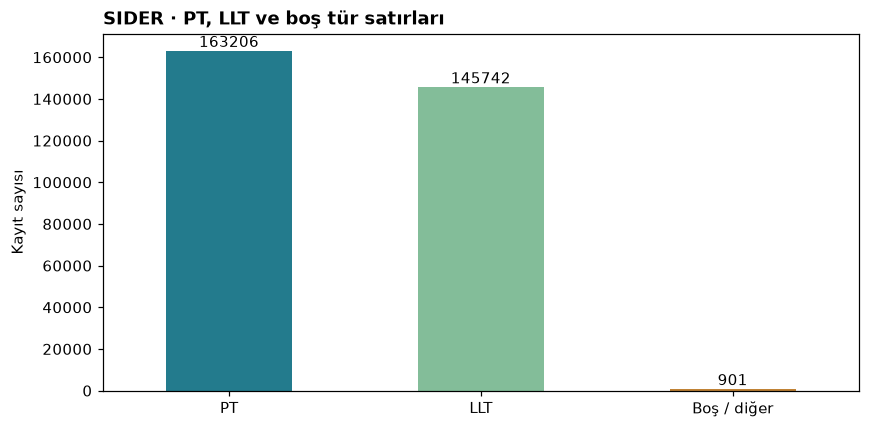

,id,name,cid,conservative,flat_id,stereo_id,label_cui,meddra_cui,term,source_line
9,DB00196,Fluconazole,3365,False,CID100003365,CID000003365,C0004093,C0004093,Asthenia,69696
33,DB00196,Fluconazole,3365,False,CID100003365,CID000003365,C0015672,C0004093,Asthenia,69742
23,DB00196,Fluconazole,3365,False,CID100003365,CID000003365,C0011991,C0011991,Diarrhoea,69724
143,DB00196,Fluconazole,3365,False,CID100003365,CID000003365,C2129214,C0011991,Diarrhoea,69951
76,DB00196,Fluconazole,3365,False,CID100003365,CID000003365,C0037274,C0037274,Skin disorder,69824
108,DB00196,Fluconazole,3365,False,CID100003365,CID000003365,C0178298,C0037274,Skin disorder,69884
101,DB00196,Fluconazole,3365,False,CID100003365,CID000003365,C0151849,C0852911,Blood alkaline phosphatase increased,69870
135,DB00196,Fluconazole,3365,False,CID100003365,CID000003365,C0852911,C0852911,Blood alkaline phosphatase increased,69935
147,DB00199,Erythromycin,12560,True,CID100003255,CID000012560,C0000729,C0000737,Abdominal pain,64043
149,DB00199,Erythromycin,12560,True,CID100003255,CID000012560,C0000737,C0000737,Abdominal pain,64046


,anahtar,tekrar fazlası
0,Tüm satır,0
1,stereo + tür + CUI,10840


In [4]:
display(pd.DataFrame([quality]).drop(columns=['missing','type_counts','invalid_stitch_pairs']))
display(pd.DataFrame({'alan':list(quality['missing']),'boş':list(quality['missing'].values()),'payda':quality['rows']}))
types=pd.Series(quality['type_counts']).rename(index={'':'Boş / diğer'})
ax=types.plot.bar(figsize=(8,4),rot=0,color=['#237b8d','#83bd99','#c08235']);ax.bar_label(ax.containers[0])
finish('01_pt_llt','SIDER · PT, LLT ve boş tür satırları')
dup=evidence[evidence.duplicated(['id','meddra_cui'],keep=False)]
display(dup.sort_values(['id','meddra_cui']).head(12))
display(pd.DataFrame({'anahtar':['Tüm satır','stereo + tür + CUI'],
 'tekrar fazlası':[quality['duplicate_full_rows_excess'],quality['duplicate_stereo_type_cui_excess']]}))

**Yorum:** Bu tekrarlar yeni yan etki kanıtı olarak sayılmaz. Kaynak satırı `pt_evidence.csv` içinde korunur; `drug_pt_positives.csv` ilaç–CUI çiftini tekilleştirir. Yerel dosyadaki PT kapsam sayısı yayınlardaki tüm SIDER ADR sayılarıyla aynı tanımda olmayabilir; burada sayılar bu dosyadan hesaplanır.

## 4 DrugBank adaylarında eşleme başarısı ve belirsiz vaka

237 ve 233 listeleri WP02'den okunur. Adaylara yeni CID üretilmez. Tuz/ana ilaç ilişkisi kimlik provenansında tutulur; tuz CID'si veya formülasyon eşdeğerliği mevcut değilse otomatik etiket aktarımı yapılmaz.

,candidates,cid_available,status_counts,exact_sider,with_pt,chemistry_and_pt,protein_and_pt,all_three,missing_chemistry_with_pt,missing_protein_with_pt,new_vs_old38,retained_old38,old_adr_but_missing_now,positive_drug_pt_pairs,code_category_pairs_audit,historical_category_pairs_audit,with_historical_category_audit,with_code_category_audit
broad,237,171,"{'unmatched_cid_not_in_sider': 106, 'unmatched...",64,64,42,57,36,22,7,37,27,[],6616,1011,1045,63,63
conservative,233,167,"{'unmatched_cid_not_in_sider': 104, 'unmatched...",62,62,41,55,35,21,7,36,26,[],6416,977,1011,61,61


,id,name,cid,flat_ids,stereo_ids,status
140,DB06402,Telavancin,3081362,['CID103081362'],['CID045267081'],ambiguous_flat_only


,parent_id,salt_id,salt_name,parent_mapping_status,salt_compound_cid,label_transfer
0,DB00199,DBSALT001358,Erythromycin estolate,exact_stereo_cid,not_available_in_WP02,not_performed
1,DB00199,DBSALT001220,Erythromycin ethylsuccinate,exact_stereo_cid,not_available_in_WP02,not_performed
2,DB00199,DBSALT001340,Erythromycin gluceptate,exact_stereo_cid,not_available_in_WP02,not_performed
3,DB00199,DBSALT001219,Erythromycin lactobionate,exact_stereo_cid,not_available_in_WP02,not_performed
4,DB00199,DBSALT001624,Erythromycin phosphate,exact_stereo_cid,not_available_in_WP02,not_performed
5,DB00199,DBSALT001221,Erythromycin stearate,exact_stereo_cid,not_available_in_WP02,not_performed
6,DB00199,DBSALT002260,Erythromycin sulfate,exact_stereo_cid,not_available_in_WP02,not_performed
7,DB00199,DBSALT001625,Erythromycin thiocyanate,exact_stereo_cid,not_available_in_WP02,not_performed
8,DB00207,DBSALT000882,Azithromycin dihydrate,exact_stereo_cid,not_available_in_WP02,not_performed
9,DB00207,DBSALT003207,Azithromycin hemiethanolate monohydrate,exact_stereo_cid,not_available_in_WP02,not_performed


,status,ilaç sayısı
0,unmatched_cid_not_in_sider,104
1,unmatched_no_cid,66
2,exact_stereo_cid,62
3,ambiguous_flat_only,1


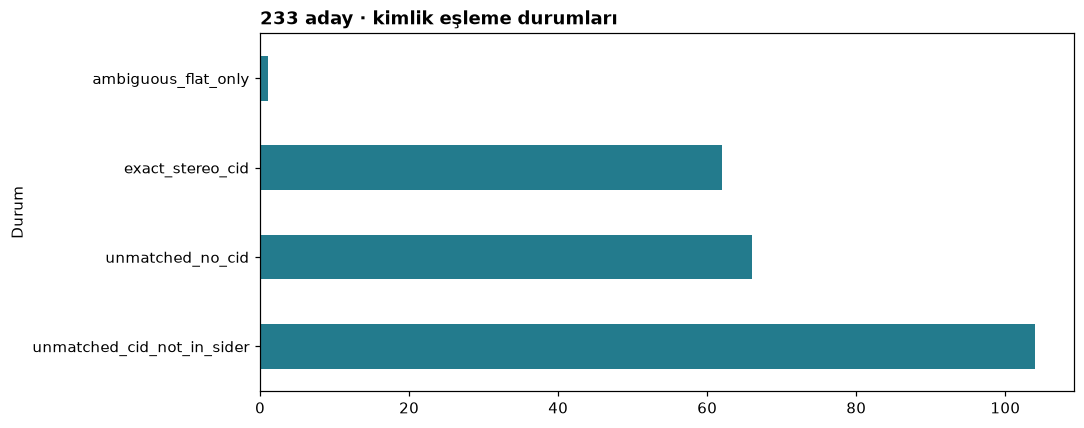

,id,name,conservative,cid,status
0,DB00080,Daptomycin,True,16134395,unmatched_cid_not_in_sider
1,DB00218,Moxifloxacin,True,152946,unmatched_cid_not_in_sider
2,DB00229,Cefotiam,True,43708,unmatched_cid_not_in_sider
3,DB00256,Lymecycline,True,54707177,unmatched_cid_not_in_sider
4,DB00263,Sulfisoxazole,True,5344,unmatched_cid_not_in_sider
5,DB00267,Cefmenoxime,True,9570757,unmatched_cid_not_in_sider
6,DB00274,Cefmetazole,True,42008,unmatched_cid_not_in_sider
7,DB00355,Aztreonam,True,9568617,unmatched_cid_not_in_sider
8,DB00365,Grepafloxacin,True,72474,unmatched_cid_not_in_sider
9,DB00430,Cefpiramide,True,636405,unmatched_cid_not_in_sider


In [5]:
display(pd.DataFrame(coverage).T)
display(pop[pop.status.str.startswith('ambiguous')][['id','name','cid','flat_ids','stereo_ids','status']])
display(read('salt_mapping_review.csv').head(10))
counts=pop.status.value_counts();display(counts.rename('ilaç sayısı').reset_index())
counts.plot.barh(figsize=(10,4),color='#237b8d');finish('02_mapping_status','233 aday · kimlik eşleme durumları','Durum')
display(read('unmatched_or_ambiguous.csv')[['id','name','conservative','cid','status']].head(20))

**Telavancin örneği:** DrugBank CID 3081362 için flat CID103081362 görülüyor; kaynak stereo CID045267081, yani CID 45267081. Bu iki CID eşit değil. İlaç adını veya flat grubu gerekçe göstererek kesin kabul etmedik. “CID SIDER'da yok” da “ilaçta yan etki yok” anlamına gelmez; mevcut kimlikle eşleşme bulunmadı demektir.

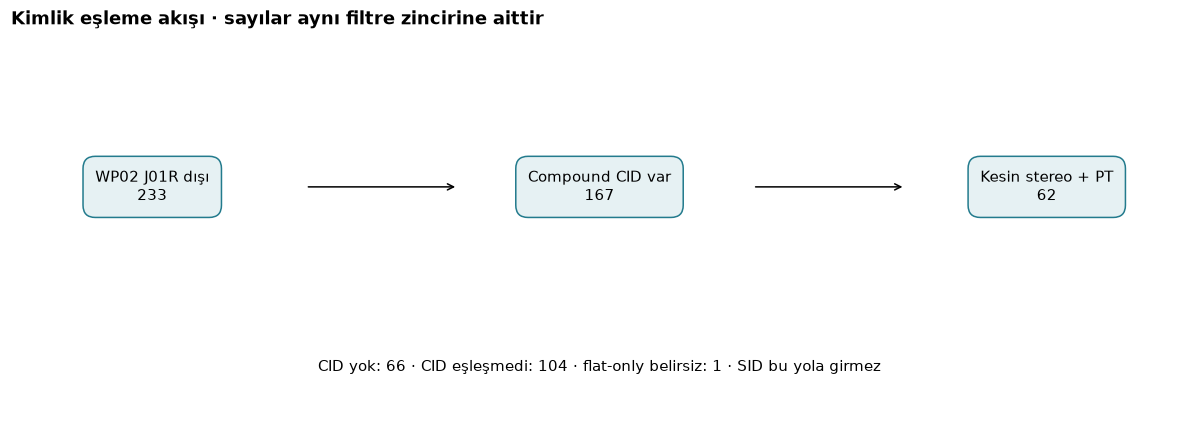

In [6]:
fig,ax=plt.subplots(figsize=(11,4));ax.axis('off')
values=[('WP02 J01R dışı',coverage['conservative']['candidates']),('Compound CID var',coverage['conservative']['cid_available']),('Kesin stereo + PT',coverage['conservative']['with_pt'])]
for x,(label,n) in zip([.12,.5,.88],values):ax.text(x,.6,f'{label}\n{n}',ha='center',va='center',bbox=dict(boxstyle='round,pad=.8',fc='#e6f1f3',ec='#237b8d'),transform=ax.transAxes)
for a,b in [(.25,.38),(.63,.76)]:ax.annotate('',xy=(b,.6),xytext=(a,.6),xycoords='axes fraction',arrowprops=dict(arrowstyle='->'))
ax.text(.5,.12,'CID yok: 66 · CID eşleşmedi: 104 · flat-only belirsiz: 1 · SID bu yola girmez',ha='center',transform=ax.transAxes)
finish('03_identity_flow','Kimlik eşleme akışı · sayılar aynı filtre zincirine aittir')

**Akış yorumu:** Kaynak-J01 kapsamı ve etiketlenebilir ilaç kümesi aynı değildir. Doğrudan stereo eşleşmesi dışındaki yollar ayrı inceleme listesinde kalır; sayıyı artırmak için zorlanmaz.

## 5 Gerçek PT kapsamı ve eksik modaliteler

Aşağıdaki “kimya mevcut” bayrağı eski feature tablosunda beş fizikokimyasal özelliğin bulunmasıdır; yeni SMILES/molekül grafı hazır demek değildir. “Protein mevcut” WP02 XML kimlik kontrolüdür; protein özellikleri henüz üretilmedi. Hiçbir bayrak etiketlerden türetilmiş model girdisi değildir; yalnız QA kapsam göstergesidir.

,id,name,pt_count,chemistry_available,protein_available,old38
2,DB00199,Erythromycin,56,True,True,False
3,DB00207,Azithromycin,177,True,True,False
6,DB00254,Doxycycline,150,True,False,False
8,DB00259,Sulfanilamide,2,True,True,False
12,DB00301,Flucloxacillin,61,True,True,True
...,...,...,...,...,...,...
127,DB02703,Fusidic acid,44,False,True,False
131,DB04911,Oritavancin,46,False,True,False
137,DB06211,Doripenem,33,True,True,True
141,DB06590,Ceftaroline fosamil,44,False,True,False


,id,name,chemistry_available,protein_available,pt_count
0,DB00254,Doxycycline,True,False,150
1,DB00438,Ceftazidime,False,True,79
2,DB00479,Amikacin,False,True,27
3,DB00493,Cefotaxime,False,True,58
4,DB00512,Vancomycin,True,False,80
5,DB00535,Cefdinir,False,True,100
6,DB00567,Cephalexin,False,True,76
7,DB00601,Linezolid,True,False,115
8,DB00671,Cefixime,False,True,49
9,DB00684,Tobramycin,True,False,158


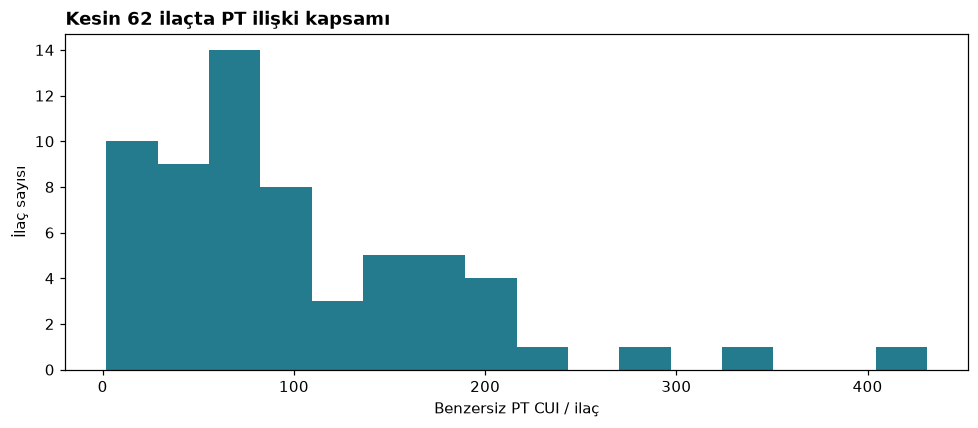

,id,name,cid,conservative,meddra_cui,term
143,DB00199,Erythromycin,12560,True,C0000737,Abdominal pain
144,DB00199,Erythromycin,12560,True,C0687713,Gastrointestinal pain
145,DB00199,Erythromycin,12560,True,C0002792,Anaphylactic shock
146,DB00199,Erythromycin,12560,True,C0232462,Decreased appetite
147,DB00199,Erythromycin,12560,True,C0003811,Arrhythmia
148,DB00199,Erythromycin,12560,True,C0008031,Chest pain
149,DB00199,Erythromycin,12560,True,C0008149,Chlamydial infection
150,DB00199,Erythromycin,12560,True,C0009676,Confusional state
151,DB00199,Erythromycin,12560,True,C1443060,Feeling abnormal
152,DB00199,Erythromycin,12560,True,C0011991,Diarrhoea


In [7]:
display(accepted[['id','name','pt_count','chemistry_available','protein_available','old38']])
display(read('missing_modalities.csv')[['id','name','chemistry_available','protein_available','pt_count']])
accepted.pt_count.plot.hist(bins=16,figsize=(9,4),color='#237b8d');plt.xlabel('Benzersiz PT CUI / ilaç')
finish('04_pt_per_drug','Kesin 62 ilaçta PT ilişki kapsamı','İlaç sayısı')
display(u[u.conservative].head(12))

**Yorum:** PT sayısı raporlama ve kaynak kapsamını gösterir; yan etki risk skoru veya klinik prevalans değildir. Yeni ilaçların kimyası eksik diye PT pozitifleri atılmaz. SIDER kaydı yokluğu negatif sınıf değildir.

## 6 Üç kaynağın kesişimleri — UpSet görünümü

233 adayın her biri, PT / mevcut kimya / XML protein bayraklarının tek bir kombinasyonuna girer. Çubuklar **ayrık** kesişimlerdir; toplamları 233 eder. PT dışındaki kaynak kapsamı, eksik etiketi gerçek negatif yapmaz.

,has_pt,chemistry_available,protein_available,count
1,False,False,True,108
0,False,False,False,63
5,True,True,True,35
3,True,False,True,20
4,True,True,False,6
2,True,False,False,1


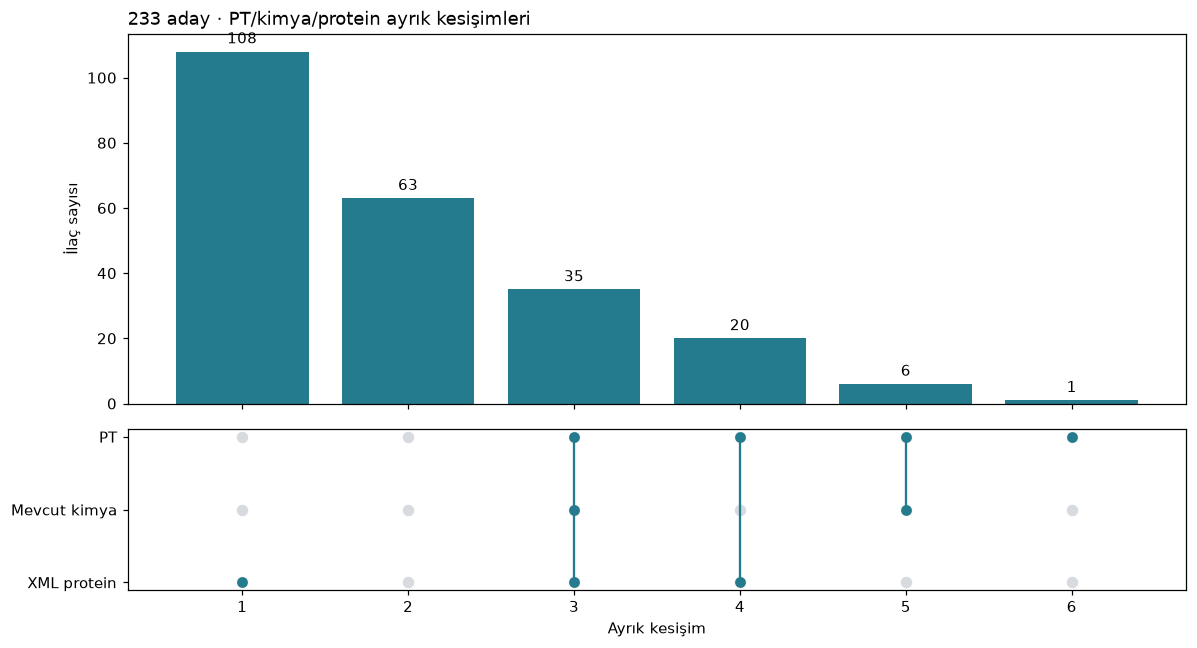

,gösterge,ilaç
0,Eski karışık havuz,38
1,Eski havuzun J01R dışı kısmı,26
2,Yeni kesin PT kapsamı,62
3,Eski 30 kategori denetimi,61


In [8]:
cols=['has_pt','chemistry_available','protein_available']
intersections=pop.groupby(cols).size().rename('count').reset_index().sort_values('count',ascending=False)
display(intersections);intersections.to_csv(QA/'modality_intersections.csv',index=False,encoding='utf-8-sig')
fig,(ax,mat)=plt.subplots(2,1,figsize=(11,6),gridspec_kw={'height_ratios':[3,1.3]},sharex=True)
x=list(range(len(intersections)));bars=ax.bar(x,intersections['count'],color='#237b8d');ax.bar_label(bars,padding=3);ax.set_ylabel('İlaç sayısı')
for i,(_,r) in enumerate(intersections.iterrows()):
    active=[j for j,k in enumerate(cols) if r[k]]
    mat.plot([i]*3,list(range(3)),'.',color='#d7dbdf',markersize=13)
    if active:mat.plot([i]*len(active),active,'o-',color='#237b8d')
mat.set_yticks(range(3),['PT','Mevcut kimya','XML protein']);mat.set_xticks(x,[str(i+1) for i in x]);mat.set_xlabel('Ayrık kesişim');mat.invert_yaxis()
ax.set_title('233 aday · PT/kimya/protein ayrık kesişimleri',loc='left');plt.tight_layout();plt.savefig(FIG/'05_upset.png',dpi=160);plt.show()
display(pd.DataFrame({'gösterge':['Eski karışık havuz','Eski havuzun J01R dışı kısmı','Yeni kesin PT kapsamı','Eski 30 kategori denetimi'],
 'ilaç':[38,int(accepted.old38.sum()),len(accepted),coverage['conservative']['with_historical_category_audit']]}))

## 7 Eski 38 ile doğru karşılaştırma

Eski 38'in 12'si muhafazakâr J01 kapsamı dışında kaldı (WP02). Yeni 62'nin 26'sı aynı ID'ler, 36'sı eski 38 dışında. Dolayısıyla “36 yeni kimlik” ile “62−38=24 net sayı farkı” farklı karşılaştırmalardır. Ayrıca herhangi PT bulunması ile eski seçilmiş 30 kategoride ilişki bulunması ayrı koşullardır.

,id,name,pt_count,chemistry_available,protein_available
0,DB00199,Erythromycin,56,True,True
1,DB00207,Azithromycin,177,True,True
2,DB00254,Doxycycline,150,True,False
3,DB00259,Sulfanilamide,2,True,True
4,DB00438,Ceftazidime,79,False,True
5,DB00446,Chloramphenicol,52,True,True
6,DB00479,Amikacin,27,False,True
7,DB00493,Cefotaxime,58,False,True
8,DB00512,Vancomycin,80,True,False
9,DB00535,Cefdinir,100,False,True


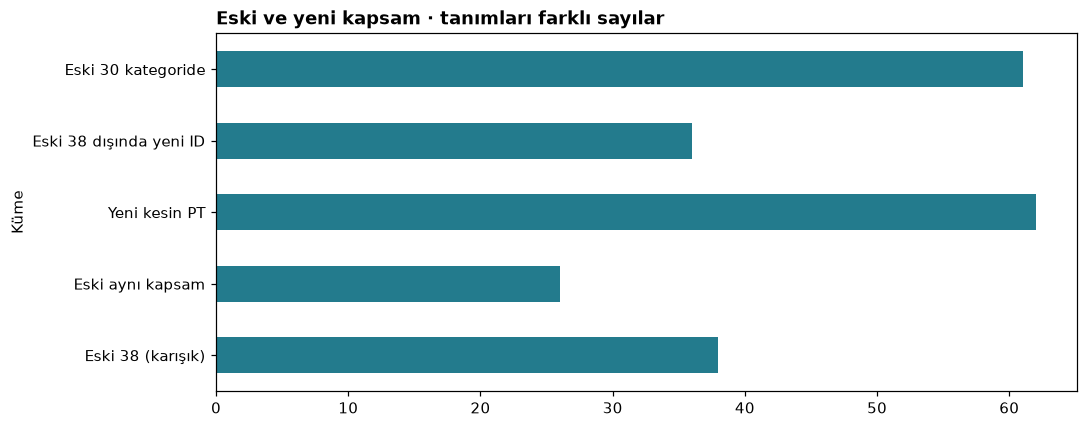

,old_rows,old_unique_drug_category,old38_rows,old38_unique_pairs,actual_categories,code_terms,code_categories,old_pt_name_absent_in_code,actual_pt_cui_to_multiple_categories,old38_unique_cui,reference_all_legacy_keys_in_raw_sider,rebuilt_old38_unique_categories_from_raw,rebuilt_old38_unique_pt_from_raw
0,865,844,605,590,30,40,33,[Pseudomembranous colitis],0,605,865,590,605


In [9]:
display(read('new_drugs_vs_old38.csv')[['id','name','pt_count','chemistry_available','protein_available']])
pd.Series({'Eski 38 (karışık)':38,'Eski aynı kapsam':26,'Yeni kesin PT':62,'Eski 38 dışında yeni ID':36,'Eski 30 kategoride':61}).plot.barh(figsize=(10,4),color='#237b8d')
finish('06_old_new','Eski ve yeni kapsam · tanımları farklı sayılar','Küme')
display(pd.DataFrame([legacy]))

**Yorum:** Sulfanilamide kaynak PT ilişkisi taşır ama tarihsel 30 kategori projeksiyonunda ilişki yoktur. Bu ilaç “yan etkisiz” değildir. Nihai kategori seçimini değiştirmeden, tüm-PT keşif kapsamı ile eski kategori denetimi ayrı tutulur.

## 8 Eski 30 kategori nasıl oluşmuş?

Eski kodun `HEDEF_35_SE` sözlüğü AST ile yalnız veri olarak okundu, çalıştırılmadı: 40 İngilizce ad → 33 Türkçe değer. Gerçek V5 dosyası 30 kategori taşıyor ve kodda olmayan Pseudomembranous colitis terimini içeriyor. Bu bir revizyon farkıdır; eski kodun çıktıyı bire bir ürettiği varsayılmaz.

Eski kategori sözlüğü yalnız denetim amacıyla kaynak PT-CUI'lere yansıtıldı; nihai hedef etiketi onayı değildir. Çok PT'nin aynı kategoriye gitmesi ve etiket-CUI tekrarları ayrı azaltım adımlarıdır.

,category,pt_names,cuis,n_cui,n_names,code_categories,code_missing_terms
0,Alerjik reaksiyon,[Hypersensitivity],[C0020517],1,1,[Alerjik reaksiyon],[]
1,Anemi,[Anaemia],[C0002871],1,1,[Anemi],[]
2,Ağız mantarı,[Oral candidiasis],[C0006849],1,1,[Ağızda mantar enfeksiyonu],[]
3,Baş ağrısı,[Headache],[C0018681],1,1,[Baş ağrısı],[]
4,Baş dönmesi,[Dizziness],[C0012833],1,1,[Baş dönmesi],[]
5,Bilinç kaybı,"[Loss of consciousness, Syncope]","[C0039070, C0041657]",2,2,[Bilinç kaybı],[]
6,C.diff ishal,"[Clostridium difficile colitis, Pseudomembrano...","[C0238106, C1257843]",2,2,[C. diff ilişkili ishal],[Pseudomembranous colitis]
7,Deri döküntüsü,[Rash],[C0015230],1,1,[Deri döküntüsü],[]
8,Hazımsızlık,[Dyspepsia],[C0013395],1,1,[Hazımsızlık],[]
9,Hırıltı,[Wheezing],[C0043144],1,1,[Hırıltı],[]


,category,pt_names,cuis,n_cui,n_names,code_categories,code_missing_terms
0,Bilinç kaybı,"[Loss of consciousness, Syncope]","[C0039070, C0041657]",2,2,[Bilinç kaybı],[]
1,C.diff ishal,"[Clostridium difficile colitis, Pseudomembrano...","[C0238106, C1257843]",2,2,[C. diff ilişkili ishal],[Pseudomembranous colitis]


,id,name,meddra_cui,term,category,source_line
19,DB00199,Erythromycin,C0000737,Abdominal pain,Karın ağrısı,64043
20,DB00199,Erythromycin,C0000737,Abdominal pain,Karın ağrısı,64046
28,DB00199,Erythromycin,C0042963,Vomiting,Kusma,64110
29,DB00199,Erythromycin,C0042963,Vomiting,Kusma,64128
40,DB00207,Azithromycin,C0012833,Dizziness,Baş dönmesi,23409
52,DB00207,Azithromycin,C0012833,Dizziness,Baş dönmesi,23539
53,DB00207,Azithromycin,C0041657,Loss of consciousness,Bilinç kaybı,23540
54,DB00207,Azithromycin,C0039070,Syncope,Bilinç kaybı,23542
34,DB00207,Azithromycin,C0000737,Abdominal pain,Karın ağrısı,23347
57,DB00207,Azithromycin,C0000737,Abdominal pain,Karın ağrısı,23613


,strateji,ilaç,tekil ilişki
0,Tüm PT CUI (keşif),62,6416
1,Gerçek V5 30 kategori sözlüğü (denetim),61,1011
2,MASTER kod sözlüğü (denetim),61,977


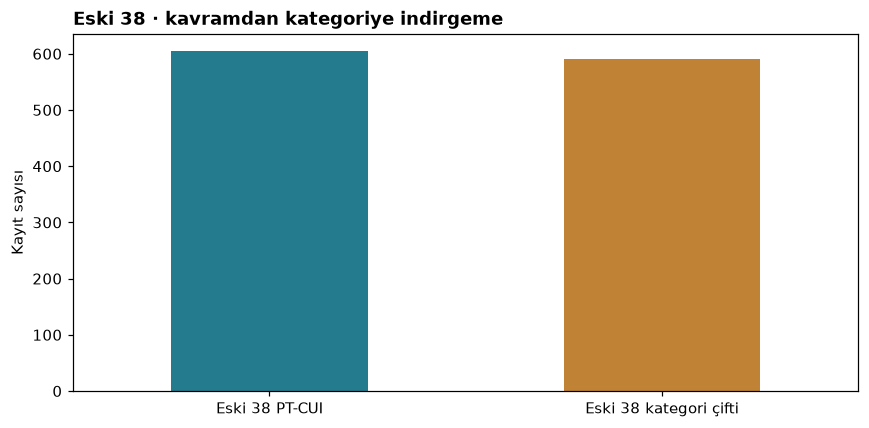

In [10]:
audit=js('category_audit.json');display(pd.DataFrame(audit))
display(pd.DataFrame([x for x in audit if x['n_cui']>1]))
hist=read('historical_category_projection_audit.csv');h=hist[hist.conservative]
display(h[h.duplicated(['id','category'],keep=False)].sort_values(['id','category']).head(12)[['id','name','meddra_cui','term','category','source_line']])
display(pd.DataFrame({'strateji':['Tüm PT CUI (keşif)','Gerçek V5 30 kategori sözlüğü (denetim)','MASTER kod sözlüğü (denetim)'],
 'ilaç':[62,coverage['conservative']['with_historical_category_audit'],coverage['conservative']['with_code_category_audit']],
 'tekil ilişki':[coverage['conservative']['positive_drug_pt_pairs'],coverage['conservative']['historical_category_pairs_audit'],coverage['conservative']['code_category_pairs_audit']]}))
pd.Series({'Eski 38 PT-CUI':legacy['old38_unique_cui'],'Eski 38 kategori çifti':legacy['old38_unique_pairs']}).plot.bar(figsize=(8,4),rot=0,color=['#237b8d','#c08235'])
finish('07_category_collapse','Eski 38 · kavramdan kategoriye indirgeme')

**Bilimsel yorum:** Loss of consciousness ve Syncope ayrı CUI'lerle aynı “Bilinç kaybı” kategorisine, iki kolit PT'si “C.diff ishal” kategorisine gidiyor. Aynı kategori adı altında farklı kavramlar birleşiyor; bu klinik eşanlamlılığı kanıtlamaz. Genel Colitis → antibiyotikle ilişkili kolit ve kodda Renal impairment → nefrotoksisite gibi çeviriler kapsamı olduğundan özgül gösterebilir. Ayrı “metalik tat/tat değişikliği” veya deri kabarcığı gibi istenen kavramlar otomatik olarak 30 kategoride temsil edilmiş sayılmaz. Harici ontoloji/hiyerarşi eklenmedi; bu yüzden kategori stratejisi yalnız mevcut CUI/adlar düzeyinde denetlendi.

## 9 Küçük etkileşimli ilaç–PT ağı

Görünürlük için kesin kümeden ilk dört ilacın ortak/çok görülen sekiz PT'si seçilir. Bu bir eğitim grafı veya tüm yan etki ağı değildir. Ok, kaynak pozitif ilişkisi anlamındadır; risk olasılığı göstermez.

In [11]:
import plotly.graph_objects as go
ids=accepted.sort_values('id').head(4).id.tolist();small=u[u.id.isin(ids)]
concepts=small.groupby('meddra_cui').id.nunique().sort_values(ascending=False).head(8).index.tolist();small=small[small.meddra_cui.isin(concepts)]
nodes=ids+concepts;positions={n:(x,1-i/max(len(ns)-1,1)) for x,ns in [(0,ids),(1,concepts)] for i,n in enumerate(ns)}
names=dict(zip(accepted.id,accepted.name));names.update(dict(zip(u.meddra_cui,u.term)))
xs=[];ys=[]
for row in small.itertuples():
    a,b=positions[row.id],positions[row.meddra_cui];xs.extend([a[0],b[0],None]);ys.extend([a[1],b[1],None])
fig=go.Figure([go.Scatter(x=xs,y=ys,mode='lines',hoverinfo='skip',line=dict(color='#9aabb5',width=1)),
go.Scatter(x=[positions[n][0] for n in nodes],y=[positions[n][1] for n in nodes],mode='markers+text',text=[names[n] for n in nodes],
 textposition='top center',hovertext=[n+'<br>'+names[n] for n in nodes],hoverinfo='text',marker=dict(size=20,color=['#237b8d']*len(ids)+['#c08235']*len(concepts)))])
fig.update_layout(title='Kesin eşleşmiş dört ilaç → sekiz PT · küçük pozitif ilişki örneği',showlegend=False,height=700,
 xaxis=dict(visible=False,range=[-.4,1.5]),yaxis=dict(visible=False,range=[-.2,1.2]),plot_bgcolor='white',margin=dict(l=100,r=100,t=80,b=60))
html=FIG/'drug_pt_network.html';fig.write_html(html,include_plotlyjs=True);display(small);display(FileLink(str(html)))

,id,name,cid,conservative,meddra_cui,term
144,DB00199,Erythromycin,12560,True,C0687713,Gastrointestinal pain
146,DB00199,Erythromycin,12560,True,C0232462,Decreased appetite
152,DB00199,Erythromycin,12560,True,C0011991,Diarrhoea
167,DB00199,Erythromycin,12560,True,C0038325,Stevens-Johnson syndrome
173,DB00199,Erythromycin,12560,True,C0042109,Urticaria
176,DB00199,Erythromycin,12560,True,C0042963,Vomiting
185,DB00199,Erythromycin,12560,True,C0234215,Discomfort
189,DB00199,Erythromycin,12560,True,C0235378,Hepatotoxicity
199,DB00207,Azithromycin,447043,True,C0687713,Gastrointestinal pain
208,DB00207,Azithromycin,447043,True,C0232462,Decreased appetite


C:\Users\emrey\Downloads\Graph-Tez-V7_SADELESTIRILMIS_CODEX\Graph-Tez-V7\reports\figures\WP03\drug_pt_network.html

## 10 Testler ve durma kapısı

Kimlik türü, flat/stereo karşı örnekleri, SID'nin kullanılmaması, çok sahipli CID, PT tekilliği ve eski 590 çiftin kaynak üzerinden yeniden doğrulanması otomatik testlerle kontrol edilir. Veri yokluğu negatif yapılmaz. Tüm ilişkiler kaynak satır numarasıyla izlenebilir; birden fazla kaynak satırı tek pozitif çifte gidebilir.

In [12]:
assert len(pop)==233 and len(accepted)==62
assert not u.duplicated(['id','meddra_cui']).any()
assert coverage['conservative']['new_vs_old38']+coverage['conservative']['retained_old38']==62
assert legacy['old38_unique_pairs']==590 and legacy['reference_all_legacy_keys_in_raw_sider']==865
assert decode_stitch('CID100000085','flat')!='100000085'
assert js('source_manifest.json')['metadata_unchanged']
display(pd.DataFrame([{'paket':'WP03','durum':'analiz tamamlandı','kesin muhafazakâr PT ilaç':62,'nihai hedef etiketi değişikliği':'yok','sonraki kapı':'kullanıcı onayı'}]))

,paket,durum,kesin muhafazakâr PT ilaç,nihai hedef etiketi değişikliği,sonraki kapı
0,WP03,analiz tamamlandı,62,yok,kullanıcı onayı
